# Person 2: Body, Clinical Measurements & DVC Exploration

**Author:** Rishabh (Person 2: Body, Clinical Measurements & DVC)  
**Course:** AI252TA — MLOps  
**Topic:** Clinical Measurements & Anthropometrics (NHANES 2017-2018 & 2021-2023)  

This notebook documents the clinical reasoning, exploratory analysis, and data cleaning decisions that power `src/data/body.py`.

## 1. Setup and Environment Verification

In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data.body import read_xpt, process_bmx, process_bp, process_bpq, process_labs, build, CONTRACT

raw_2017 = ROOT / 'data' / 'raw' / 'nhanes' / '2017-2018'
print('Environment initialized successfully.')


Environment initialized successfully.


## 2. Inspecting Raw Blood Pressure & Auscultation Quirks
In NHANES 2017-2018, manual auscultation was used with up to 4 readings. Diastolic pressure has recordings of 0 mmHg (stored as 5.4e-79 in SAS), which represent unmeasured Korotkoff sounds rather than physiological zeros.

In [2]:
bpx = pd.read_sas(raw_2017 / "BPX_J.xpt", format="xport")
print("Diastolic readings < 1e-5 (zeros):")
for i in range(1, 5):
    print(f"  BPXDI{i} zeros:", (bpx[f"BPXDI{i}"] < 1e-5).sum())

print("\nSummary of SBP readings 1 to 3:")
print(bpx[["BPXSY1", "BPXSY2", "BPXSY3"]].describe().round(1))

Diastolic readings < 1e-5 (zeros):
  BPXDI1 zeros: 134
  BPXDI2 zeros: 124
  BPXDI3 zeros: 127
  BPXDI4 zeros: 9

Summary of SBP readings 1 to 3:
       BPXSY1  BPXSY2  BPXSY3
count  6302.0  6563.0  6538.0
mean    121.3   121.6   121.2
std      20.0    20.5    20.3
min      72.0    72.0    72.0
25%     106.0   106.0   106.0
50%     118.0   118.0   118.0
75%     132.0   132.0   132.0
max     228.0   236.0   238.0


## 3. Anthropometric Consistency: Reported BMI vs Calculated BMI
Checking whether CDC reported BMXBMI matches weight_kg / (height_m)^2.

In [3]:
bmx = pd.read_sas(raw_2017 / "BMX_J.xpt", format="xport")
calc_bmi = bmx["BMXWT"] / ((bmx["BMXHT"] / 100) ** 2)
diff = (calc_bmi - bmx["BMXBMI"]).abs()
print("Maximum difference:", round(diff.max(), 4), "kg/m^2")
print("Mean difference:", round(diff.mean(), 4), "kg/m^2 (due solely to CDC rounding to 1 decimal place)")

Maximum difference: 0.05 kg/m^2
Mean difference: 0.0251 kg/m^2 (due solely to CDC rounding to 1 decimal place)


## 4. Run Topic Transformation Pipeline for 2017-2018
Executing `build('2017-2018')` and verifying output against the team data contract.

In [4]:
body_df = build("2017-2018")
print("Output shape:", body_df.shape)
print("Columns match contract:", list(body_df.columns) == CONTRACT)
body_df.head()

[2017-2018] Loading and cleaning body & clinical source files...


[2017-2018] Total participants in body dataset: 9,037
[2017-2018] Summary of missingness per clinical feature:
  - height_cm      :  1021 missing ( 11.3%)
  - weight_kg      :   457 missing (  5.1%)
  - bmi            :  1034 missing ( 11.4%)
  - waist_cm       :  1436 missing ( 15.9%)
  - sbp            :  2320 missing ( 25.7%)
  - dbp            :  2405 missing ( 26.6%)
  - pulse          :  2295 missing ( 25.4%)
  - told_high_bp   :  2886 missing ( 31.9%)
  - total_chol     :  2299 missing ( 25.4%)
  - hdl            :  2299 missing ( 25.4%)
  - hba1c          :  2992 missing ( 33.1%)
Output shape: (9037, 12)
Columns match contract: True


,seqn,height_cm,weight_kg,bmi,waist_cm,sbp,dbp,pulse,told_high_bp,total_chol,hdl,hba1c
0,93703,88.6,13.7,17.5,48.2,NaN,NaN,NaN,<NA>,NaN,NaN,NaN
1,93704,94.2,13.9,15.7,50.0,NaN,NaN,NaN,<NA>,NaN,NaN,NaN
2,93705,158.3,79.5,31.7,101.8,200.0,68.0,52.0,1,157.0,60.0,6.2
3,93706,175.7,66.3,21.5,79.3,111.3,73.3,82.0,0,148.0,47.0,5.2
4,93707,158.4,45.4,18.1,64.1,128.0,47.3,100.0,<NA>,189.0,68.0,5.6


## 5. Critical Leakage Finding: HbA1c vs Diabetes
HbA1c >= 6.5% is the clinical gold standard for diagnosing diabetes. Since diabetes is part of Person 1's prediction target, HbA1c represents direct target leakage and must not be used as an input feature in predictive modeling.

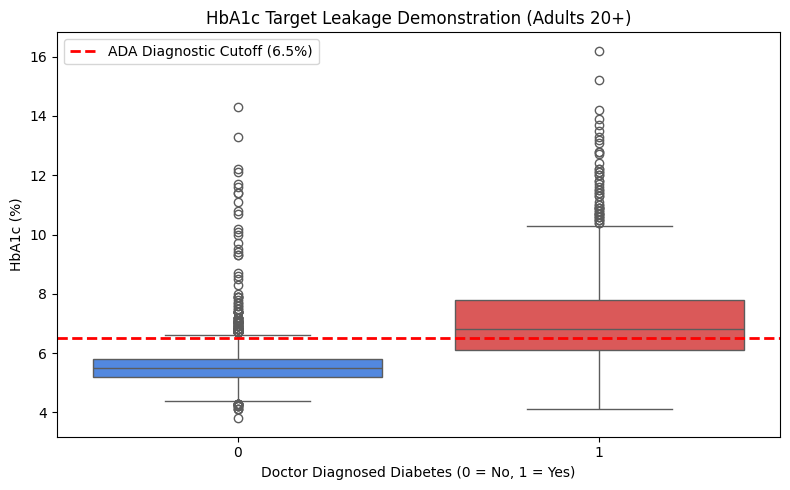

In [5]:
people_df = pd.read_csv(ROOT / "data" / "interim" / "people_2017-2018.csv")
merged = people_df.merge(body_df, on="seqn", how="inner")

plt.figure(figsize=(8, 5))
sns.boxplot(data=merged.dropna(subset=["hba1c", "diabetes"]), x="diabetes", y="hba1c", palette=["#3b82f6", "#ef4444"], hue="diabetes", legend=False)
plt.axhline(6.5, color="red", linestyle="--", linewidth=2, label="ADA Diagnostic Cutoff (6.5%)")
plt.title("HbA1c Target Leakage Demonstration (Adults 20+)")
plt.xlabel("Doctor Diagnosed Diabetes (0 = No, 1 = Yes)")
plt.ylabel("HbA1c (%)")
plt.legend()
plt.tight_layout()
plt.show()